# Leakage, drift and reset errors

Some errors cannot be written as a channel on each gate. A leaked qubit leaves the computational subspace and stays there;
a slowly drifting frequency gives the same unknown phase to every window of a shot. Both are modelled on the trajectory
engine, one shot at a time. Count keys list the classical bits from `c[n-1]` on the left to `c[0]` on the right.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:a77a42',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. Leakage

With probability `leakage_rate` per gate a qubit leaves the qubit subspace: later gates skip it and it reads as 1. GHZ₄ success falls as the rate rises.

In [2]:
target = ["0000", "1111"]
rows = []
for rate in (0.0, 0.005, 0.01, 0.02, 0.05):
    r = run("iqm_emerald", ghz(4), shots=20000, engine="trajectory",
            noise={"model": "device", "leakage_rate": rate, "seepage_rate": 0.0})
    rows.append({"leakage per gate": rate, "GHZ4 success": success(r, target),
                 "features": ", ".join(sorted(r["result"]["noise"]["features"]))})
pd.DataFrame(rows).set_index("leakage per gate").round(4)

,GHZ4 success,features
leakage per gate,,
0.000,0.8568,"depolarizing, idle_relaxation, readout, relaxa..."
0.005,0.8208,"depolarizing, idle_relaxation, leakage, readou..."
0.010,0.7950,"depolarizing, idle_relaxation, leakage, readou..."
0.020,0.7455,"depolarizing, idle_relaxation, leakage, readou..."
0.050,0.6028,"depolarizing, idle_relaxation, leakage, readou..."


## 2. Seepage brings qubits back, but not their state

`seepage_rate` is the chance per later gate that a leaked qubit returns. A returned qubit has lost its phase and the gates it skipped, so even fast seepage barely restores the GHZ state: leakage has to be prevented or detected, not waited out.

In [3]:
target = ["0000", "1111"]
rows = []
for seep in (0.0, 0.1, 0.5, 1.0):
    r = run("iqm_emerald", ghz(4), shots=20000, engine="trajectory",
            noise={"model": "device", "leakage_rate": 0.05, "seepage_rate": seep})
    rows.append({"seepage per gate": seep, "GHZ4 success": success(r, target)})
pd.DataFrame(rows).set_index("seepage per gate").round(4)

,GHZ4 success
seepage per gate,
0.0,0.6028
0.1,0.5964
0.5,0.6160
1.0,0.6255


## 3. Ramsey decay: Markovian against quasi-static

A Ramsey sequence (H, wait, H) on qubit 0 measures dephasing. The wait is made of separate CZ gates on two other qubits. Markovian T2 dephasing gives an exponential decay; a quasi-static frequency offset drawn once per shot gives a Gaussian one, which no per-window channel can produce.

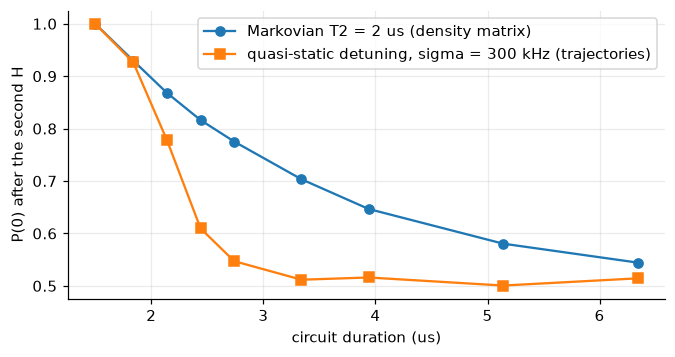

In [4]:
def ramsey(m, echo=False):
    """H, a wait of m separate CZ gates on qubits 1-2, H; with echo, an X in the middle of the wait."""
    lines = ["h q[0]"]
    for k in range(m):
        if echo and k == m // 2:
            lines += ["x q[0]", "barrier q[0],q[1],q[2]"]
        lines += ["cz q[1],q[2]", "barrier q[0],q[1],q[2]"]
    return program(3, lines + ["h q[0]"], measure=False) + "measure q[0] -> c[0];\n"

def p0(r):
    return sum(v for k, v in r["result"]["counts"].items() if k[-1] == "0") / sum(r["result"]["counts"].values())

ISOLATE = {"model": "device", "depolarizing": False, "readout": False, "coherent": False, "crosstalk": False}
MARKOV = {**ISOLATE, "relaxation": True, "idle": True, "quasi_static": False, "t1_us": 20, "t2_us": 2}
DRIFT = {**ISOLATE, "relaxation": True, "idle": True, "quasi_static_khz": 300, "t1_us": 1000, "t2_us": 1000}
waits = [0, 5, 10, 15, 20, 30, 40, 60, 80]
t_us, markov, drift = [], [], []
for m in waits:
    a = run("iqm_emerald", ramsey(m), shots=8000, noise=MARKOV)
    b = run("iqm_emerald", ramsey(m), shots=8000, noise=DRIFT, engine="trajectory")
    t_us.append(a["compilation"]["hardware_time_estimate"]["circuit_duration_us"])
    markov.append(p0(a)); drift.append(p0(b))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(t_us, markov, "o-", label="Markovian T2 = 2 us (density matrix)")
ax.plot(t_us, drift, "s-", label="quasi-static detuning, sigma = 300 kHz (trajectories)")
ax.set_xlabel("circuit duration (us)"); ax.set_ylabel("P(0) after the second H"); ax.legend(); plt.show()

## 4. A spin echo refocuses drift, not Markovian noise

An X pulse halfway through the wait reverses the phase a static offset has accumulated, so the echo cancels quasi-static drift. It cannot undo genuinely random Markovian dephasing.

In [5]:
rows = []
for m in (10, 20, 40, 80):
    rows.append({"wait (CZ gates)": m,
                 "drift, no echo": p0(run("iqm_emerald", ramsey(m), shots=8000, noise=DRIFT, engine="trajectory")),
                 "drift, echo": p0(run("iqm_emerald", ramsey(m, echo=True), shots=8000, noise=DRIFT, engine="trajectory")),
                 "Markovian, no echo": p0(run("iqm_emerald", ramsey(m), shots=8000, noise=MARKOV)),
                 "Markovian, echo": p0(run("iqm_emerald", ramsey(m, echo=True), shots=8000, noise=MARKOV))})
pd.DataFrame(rows).set_index("wait (CZ gates)").round(3)

,"drift, no echo","drift, echo","Markovian, no echo","Markovian, echo"
wait (CZ gates),,,,
10,0.778,0.998,0.868,0.862
20,0.547,0.999,0.775,0.769
40,0.516,0.998,0.647,0.644
80,0.514,0.997,0.544,0.544


## 5. Imperfect reset

`reset` returns a qubit to |0⟩. With a reset fidelity below one, some qubits prepared in |1⟩ stay there.

In [6]:
reset_test = program(1, ["x q[0]", "reset q[0]"])
rows = []
for f in (1.0, 0.999, 0.99, 0.95):
    r = run("iqm_emerald", reset_test, shots=50000,
            noise={"model": "device", "reset_fidelity": f, "readout": False, "depolarizing": False, "relaxation": False})
    rows.append({"reset fidelity": f, "P(0) after reset": success(r, ["0"])})
pd.DataFrame(rows).set_index("reset fidelity").round(4)

,P(0) after reset
reset fidelity,
1.000,1.0000
0.999,0.9991
0.990,0.9907
0.950,0.9499


## Takeaways

- Leakage and quasi-static drift are time-correlated, so they run on the trajectory engine.
- Gaussian Ramsey decay and echo refocusing are signatures of slow drift that a per-gate channel cannot reproduce.